# ET 610 Group Assignment: Learning Behaviour in OULAD and Moodle

**Team:** Karan Bansal (24B3003) · Aditya Koli (24B3024) · Keshav Kumar (24B0354)
**Report:** [`Report.pdf`](Report.pdf)

This notebook contains the full analysis behind the report, in the same order as the report:

| Part | Content | Report section |
|---|---|---|
| 0 | Setup | – |
| 1 | OULAD preprocessing and feature tables | §2.1, §3 |
| 2 | **H1** – early engagement vs demographics (logistic regression, random forest) | §5.1 |
| 3 | **H2** – first-assessment timeliness (χ², adjusted logistic regression) | §5.2 |
| 4 | Moodle preprocessing: ID recovery, filtering, sessionisation | §2.2 |
| 5 | **H3** – pre-evaluation engagement and completion (logistic inference, ML) | §5.3 |
| 6 | **H4** – deadline-driven activity (Wilcoxon signed-rank tests) | §5.4 |
| 7 | Temporal and results figures | §4, §5 |

**Data.** Raw data is not stored in the repository (see `data/README.md`). Place the seven OULAD CSV files in `data/oulad/` and `MOODLE_Data.csv` in `data/moodle/`, then run all cells from the repository root. A full run takes about 5–10 minutes; random seeds are fixed. Intermediate tables are written to `artifacts/` and figures to `figures/`.

## 0. Setup

In [1]:
import os, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
%matplotlib inline

# run from the repository root (re-running this cell is safe)
ROOT = Path.cwd().parent if Path.cwd().name == 'artifacts' else Path.cwd()
OULAD = ROOT / 'data' / 'oulad'      # the seven OULAD csv files
MOODLE = ROOT / 'data' / 'moodle'    # MOODLE_Data.csv
ART = ROOT / 'artifacts'             # intermediate tables and model results
FIGS = ROOT / 'figures'
for d in (ART, FIGS):
    d.mkdir(exist_ok=True)
os.chdir(ART)
print('working directory set to artifacts/')

working directory set to artifacts/


## 1. OULAD: preprocessing

Join `studentInfo`, `studentRegistration`, `studentVle`, `vle`, `assessments` and `studentAssessment`; group activity types into content / forum / quiz / homepage; define **at-risk = Fail or Withdrawn**; build daily and weekly click tables.

In [2]:
import pandas as pd, numpy as np
D=str(OULAD)+'/'
K=['code_module','code_presentation','id_student']
si=pd.read_csv(D+'studentInfo.csv'); reg=pd.read_csv(D+'studentRegistration.csv')
ass=pd.read_csv(D+'assessments.csv'); sa=pd.read_csv(D+'studentAssessment.csv')
vle=pd.read_csv(D+'vle.csv')[['id_site','code_module','code_presentation','activity_type']]
v=pd.read_csv(D+'studentVle.csv',dtype={'code_module':'category','code_presentation':'category','id_student':'int32','id_site':'int32','date':'int16','sum_click':'int16'})
for c in ['code_module','code_presentation']:
    v[c]=v[c].astype(str); vle[c]=vle[c].astype(str)
v=v.merge(vle,on=['id_site','code_module','code_presentation'],how='left')
grp={'forumng':'forum','oucollaborate':'forum','quiz':'quiz','externalquiz':'quiz','questionnaire':'quiz',
     'homepage':'home','resource':'content','oucontent':'content','subpage':'content','page':'content','url':'content',
     'glossary':'content','ouwiki':'content','folder':'content','htmlactivity':'content','dataplus':'content',
     'dualpane':'content','repeatactivity':'content','sharedsubpage':'content','ouelluminate':'content'}
v['grp']=v.activity_type.map(grp).fillna('content')
v['id_site']=v.id_site.astype('int32')
base=si.merge(reg[K+['date_registration','date_unregistration']],on=K,how='left')
base['at_risk']=base.final_result.isin(['Withdrawn','Fail']).astype(int)
base.to_pickle('base.pkl')

In [3]:
# weekly (dense) clicks per group for temporal plots
v['week']=np.floor(v.date/7).astype('int16')
wk=v.groupby(K+['week','grp'],observed=True).sum_click.sum().unstack('grp',fill_value=0).reset_index()
wk.to_pickle('weekly.pkl')

In [4]:
# keep compact daily table for cutoff features
dd=v.groupby(K+['date','grp'],observed=True).sum_click.sum().unstack('grp',fill_value=0).reset_index()
dd['clicks']=dd[['content','forum','home','quiz']].sum(axis=1)
nsites=v.groupby(K+['date']).id_site.nunique().rename('nsites').reset_index()
dd=dd.merge(nsites,on=K+['date'])
dd.to_pickle('daily.pkl')
print(dd.shape, base.shape)

(1808119, 10) (32593, 15)


## 2. H1 – Early engagement versus demographics (OULAD)

Features at cut-off day *c* use only data up to day *c*, and only students still registered at *c* are included. Logistic regression and random forest are evaluated with 5-fold **GroupKFold by student**, on three nested feature sets (demographics → + clickstream → + assessment behaviour), then retrained at cut-offs from day 7 to day 180.

In [5]:
import pandas as pd, numpy as np, json, warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, f1_score, average_precision_score
K=['code_module','code_presentation','id_student']
base=pd.read_pickle('base.pkl'); dd=pd.read_pickle('daily.pkl')
ass=pd.read_csv(OULAD/'assessments.csv'); sa=pd.read_csv(OULAD/'studentAssessment.csv')
a=ass[ass.assessment_type!='Exam'].dropna(subset=['date'])
sa=sa.merge(a,on='id_assessment')

def feats(c):
    pop=base[(base.date_unregistration.isna())|(base.date_unregistration>c)].copy()
    d=dd[dd.date<=c]
    g=d.groupby(K)
    f=g.agg(clicks=('clicks','sum'),active_days=('date','nunique'),forum=('forum','sum'),quiz=('quiz','sum'),
            content=('content','sum'),home=('home','sum'),nsites=('nsites','sum')).reset_index()
    pre=d[d.date<0].groupby(K).clicks.sum().rename('pre_clicks').reset_index()
    late=d[d.date>c-14].groupby(K).clicks.sum().rename('last14').reset_index()
    first=d[(d.date>=0)&(d.date<14)].groupby(K).clicks.sum().rename('first14').reset_index()
    # gaps between active days
    d2=d.sort_values(K+['date']).copy(); d2['gap']=d2.groupby(K).date.diff()
    gs=d2.groupby(K).gap.agg(gap_mean='mean',gap_max='max',gap_std='std').reset_index()
    f=f.merge(pre,on=K,how='left').merge(late,on=K,how='left').merge(first,on=K,how='left').merge(gs,on=K,how='left')
    f=pop.merge(f,on=K,how='left')
    for col in ['clicks','active_days','forum','quiz','content','home','nsites','pre_clicks','last14','first14']: f[col]=f[col].fillna(0)
    f['gap_mean']=f.gap_mean.fillna(c); f['gap_max']=f.gap_max.fillna(c); f['gap_std']=f.gap_std.fillna(0)
    f['gap_cv']=f.gap_std/f.gap_mean.replace(0,np.nan); f['gap_cv']=f.gap_cv.fillna(0)
    f['clicks_per_day']=f.clicks/f.active_days.replace(0,np.nan); f['clicks_per_day']=f.clicks_per_day.fillna(0)
    f['forum_share']=f.forum/f.clicks.replace(0,np.nan); f['forum_share']=f.forum_share.fillna(0)
    f['quiz_share']=f.quiz/f.clicks.replace(0,np.nan); f['quiz_share']=f.quiz_share.fillna(0)
    f['trend']=(f.last14+1)/(f.first14+1)
    f['active_frac']=f.active_days/max(c+1,1)
    # assessments with deadline <= c
    s=sa[sa.date<=c].copy()
    due=a[a.date<=c].groupby(['code_module','code_presentation']).size().rename('n_due').reset_index()
    sub=s[s.date_submitted<=c].copy(); sub['lat']=sub.date_submitted-sub.date
    sg=sub.groupby(K[::-1][0:0] or ['code_module','code_presentation','id_student']).agg(
        n_sub=('id_assessment','count'),lat_mean=('lat','mean'),lat_first=('lat','first'),
        late_share=('lat',lambda x:(x>0).mean()),score_mean=('score','mean')).reset_index()
    f=f.merge(due,on=['code_module','code_presentation'],how='left').merge(sg,on=K,how='left')
    f['n_due']=f.n_due.fillna(0); f['n_sub']=f.n_sub.fillna(0)
    f['sub_rate']=np.where(f.n_due>0,f.n_sub/f.n_due.replace(0,np.nan),np.nan)
    f['has_due']=(f.n_due>0).astype(int)
    f['sub_rate']=f.sub_rate.fillna(0)
    f['missed']=(f.n_due-f.n_sub).clip(lower=0)
    for col,fill in [('lat_mean',0),('lat_first',0),('late_share',0),('score_mean',-1)]: f[col]=f[col].fillna(fill)
    f['cutoff']=c
    return f

DEMO=['num_of_prev_attempts','studied_credits','date_registration']

**Design matrix** for each feature set (demographics, clickstream, assessment).

In [6]:
def design(f,sets):
    X=pd.DataFrame(index=f.index)
    X['num_of_prev_attempts']=f.num_of_prev_attempts; X['studied_credits']=f.studied_credits; X['reg_offset']=f.date_registration.fillna(0)
    cat=pd.get_dummies(f[['gender','highest_education','age_band','disability','code_module']].astype(str),drop_first=True)
    imd=f.imd_band.map({'0-10%':5,'10-20':15,'10-20%':15,'20-30%':25,'30-40%':35,'40-50%':45,'50-60%':55,'60-70%':65,'70-80%':75,'80-90%':85,'90-100%':95})
    X['imd']=imd.fillna(imd.median())
    X=pd.concat([X,cat],axis=1)
    clk=['clicks','active_days','clicks_per_day','forum_share','quiz_share','gap_mean','gap_max','gap_cv','pre_clicks','trend','active_frac','nsites']
    asm=['n_sub','sub_rate','missed','lat_mean','lat_first','late_share','score_mean','has_due']
    if 'clk' in sets:
        for c in clk: X[c]=np.log1p(f[c]) if c in ['clicks','pre_clicks','nsites','clicks_per_day'] else f[c]
    if 'asm' in sets:
        for c in asm: X[c]=f[c]
    return X.astype(float)

**Cross-validation** grouped by student; metrics from pooled out-of-fold predictions.

In [7]:
def cv(X,y,grp,model='rf',seed=0):
    gkf=GroupKFold(n_splits=5); p=np.zeros(len(y))
    for tr,te in gkf.split(X,y,grp):
        if model=='rf': m=RandomForestClassifier(n_estimators=80,max_depth=14,min_samples_leaf=5,n_jobs=1,random_state=seed,class_weight='balanced_subsample')
        else: m=make_pipeline(StandardScaler(),LogisticRegression(max_iter=500,class_weight='balanced',C=0.5))
        m.fit(X.iloc[tr],y.iloc[tr]); p[te]=m.predict_proba(X.iloc[te])[:,1]
    # threshold via max F1 on pooled OOF (reported as optimistic F1) -> use 0.5 for balanced weights
    yhat=(p>=0.5).astype(int)
    return dict(auc=roc_auc_score(y,p),ap=average_precision_score(y,p),f1=f1_score(y,yhat),prev=float(y.mean()),n=int(len(y))),p

**Feature-set ablation at day 56.**

In [8]:
res={}
F56=feats(56); F56.to_pickle('F56.pkl')
y=F56.at_risk; grp=F56.id_student
for name,sets in [('Demographics',[]),('+ Clickstream',['clk']),('+ Clickstream + Assessment',['clk','asm'])]:
    X=design(F56,sets)
    for mdl in ['lr','rf']:
        r,p=cv(X,y,grp,mdl); res[f'{name}|{mdl}']=r; print(name,mdl,r,flush=True)
        if name.startswith('+ Clickstream +') and mdl=='rf': F56['p_rf']=p

Demographics lr {'auc': 0.6476961863777775, 'ap': 0.5625961976905223, 'f1': 0.5581375553285666, 'prev': 0.4199155418143428, 'n': 26522}


Demographics rf {'auc': 0.6413409654432699, 'ap': 0.5536511137901639, 'f1': 0.5442105263157895, 'prev': 0.4199155418143428, 'n': 26522}


+ Clickstream lr {'auc': 0.768023834332758, 'ap': 0.7266568873594625, 'f1': 0.6565133426966292, 'prev': 0.4199155418143428, 'n': 26522}


+ Clickstream rf {'auc': 0.7683999868217355, 'ap': 0.7338715629852144, 'f1': 0.6362824789738288, 'prev': 0.4199155418143428, 'n': 26522}


+ Clickstream + Assessment lr {'auc': 0.8159078926860894, 'ap': 0.7924678631963019, 'f1': 0.692981655562654, 'prev': 0.4199155418143428, 'n': 26522}


+ Clickstream + Assessment rf {'auc': 0.8238720553939999, 'ap': 0.8003980204450547, 'f1': 0.6951902096575278, 'prev': 0.4199155418143428, 'n': 26522}


**Behaviour-only model** (no demographics).

In [9]:
# clickstream-only (no demographics) ablation
Xc=design(F56,['clk','asm'])[[c for c in design(F56,['clk','asm']).columns if c not in ['num_of_prev_attempts','studied_credits','reg_offset','imd'] and not c.startswith(('gender','highest','age','disability','code_module'))]]
r,p=cv(Xc,y,grp,'rf'); res['Behaviour only (no demographics)|rf']=r; print('beh only',r,flush=True)

beh only {'auc': 0.8126007406966662, 'ap': 0.7891906915543581, 'f1': 0.6836792452830188, 'prev': 0.4199155418143428, 'n': 26522}


**Cut-off sweep:** how early can at-risk students be identified? (slowest cell, ~3–4 minutes)

In [10]:
# cutoff sweep
sweep=[]
for c in [7,14,28,42,56,84,120,180]:
    Fc=feats(c); Xc=design(Fc,['clk','asm']); r,_=cv(Xc,Fc.at_risk,Fc.id_student,'rf'); r['cutoff']=c; sweep.append(r); print(c,r,flush=True)
    Xd=design(Fc,[]); rd,_=cv(Xd,Fc.at_risk,Fc.id_student,'rf'); sweep[-1]['auc_demo']=rd['auc']

7 {'auc': 0.722487738937535, 'ap': 0.6985397068762222, 'f1': 0.6421328220067112, 'prev': 0.4727191719788882, 'n': 29178, 'cutoff': 7}


14 {'auc': 0.7254306601734988, 'ap': 0.6868717363129035, 'f1': 0.627975115392334, 'prev': 0.45286105480280237, 'n': 28119, 'cutoff': 14}


28 {'auc': 0.7798113485408565, 'ap': 0.7561520951975099, 'f1': 0.6627665106604265, 'prev': 0.44131745224780305, 'n': 27538, 'cutoff': 28}


42 {'auc': 0.7984527577720429, 'ap': 0.7739311720422161, 'f1': 0.6773496579042132, 'prev': 0.4306912374185909, 'n': 27024, 'cutoff': 42}


56 {'auc': 0.8238720553939999, 'ap': 0.8003980204450547, 'f1': 0.6951902096575278, 'prev': 0.4199155418143428, 'n': 26522, 'cutoff': 56}


84 {'auc': 0.847166169235362, 'ap': 0.8224324890306492, 'f1': 0.7124348319826562, 'prev': 0.40192038563209453, 'n': 25724, 'cutoff': 84}


120 {'auc': 0.8847794179932555, 'ap': 0.860377942157594, 'f1': 0.7536183478067245, 'prev': 0.3790612261371433, 'n': 24777, 'cutoff': 120}


180 {'auc': 0.9339732460427399, 'ap': 0.9090798930174692, 'f1': 0.8105222034119026, 'prev': 0.3389903329752954, 'n': 23275, 'cutoff': 180}


**Random-forest importances and logistic coefficients** (full fit at day 56).

In [11]:
# permutation/impurity importance on full fit
X=design(F56,['clk','asm']); m=RandomForestClassifier(n_estimators=150,max_depth=14,min_samples_leaf=5,n_jobs=1,random_state=0,class_weight='balanced_subsample').fit(X,y)
imp=pd.Series(m.feature_importances_,index=X.columns).sort_values(ascending=False)
lr=make_pipeline(StandardScaler(),LogisticRegression(max_iter=500,class_weight='balanced',C=0.5)).fit(X,y)
coef=pd.Series(lr[-1].coef_[0],index=X.columns).sort_values()
imp.to_pickle('oulad_imp.pkl'); coef.to_pickle('oulad_coef.pkl')
pd.DataFrame(sweep).to_pickle('oulad_sweep.pkl'); json.dump(res,open('oulad_res.json','w'),indent=1)
F56[['p_rf']].to_pickle('F56_p.pkl')
print(imp.head(10)); print(coef.head(5), coef.tail(5))

score_mean     0.170245
missed         0.063507
active_days    0.052193
sub_rate       0.048349
active_frac    0.047260
clicks         0.046735
trend          0.045337
lat_mean       0.041630
nsites         0.041065
gap_mean       0.039523
dtype: float64
score_mean        -1.134266
clicks            -0.855256
gap_max           -0.565776
code_module_GGG   -0.495295
sub_rate          -0.396000
dtype: float64 clicks_per_day     0.410688
gap_mean           0.451511
has_due            0.495295
code_module_DDD    0.521893
code_module_FFF    0.667419
dtype: float64


**Fairness check:** does the model discriminate equally well for women and men?

In [12]:
# fairness check: discrimination of the day-56 random forest by gender (out-of-fold predictions)
from sklearn.metrics import roc_auc_score
fair={g:dict(n=int(len(d)),prevalence=round(float(d.at_risk.mean()),3),auc=round(float(roc_auc_score(d.at_risk,d.p_rf)),3)) for g,d in F56.groupby('gender')}
print(fair); json.dump(fair,open('oulad_fairness.json','w'))

{'F': {'n': 11955, 'prevalence': 0.404, 'auc': 0.803}, 'M': {'n': 14567, 'prevalence': 0.433, 'auc': 0.84}}


**Temporal validation:** the grouped cross-validation mixes 2013 and 2014 runs, so we also train on the earlier presentations and test on the latest one (2014J).

In [13]:
# temporal validation: train on the earlier presentations (2013B, 2013J, 2014B), test on the latest run (2014J)
X=design(F56,['clk','asm']); tr=(F56.code_presentation!='2014J').values; te=~tr
temporal={'train_n':int(tr.sum()),'test_n':int(te.sum())}
for name,mdl in [('rf',RandomForestClassifier(n_estimators=80,max_depth=14,min_samples_leaf=5,n_jobs=1,random_state=0,class_weight='balanced_subsample')),
                 ('lr',make_pipeline(StandardScaler(),LogisticRegression(max_iter=500,class_weight='balanced',C=0.5)))]:
    mdl.fit(X[tr],y[tr]); temporal['auc_'+name]=round(float(roc_auc_score(y[te],mdl.predict_proba(X[te])[:,1])),3)
print(temporal); json.dump(temporal,open('oulad_temporal_validation.json','w'))

{'train_n': 17643, 'test_n': 8879, 'auc_rf': 0.801, 'auc_lr': 0.79}


## 3. H2 – First-assessment timeliness (OULAD)

The first assessment of each presentation is its earliest dated TMA/CMA. Students who unregistered before that deadline are excluded; a submission is *late* if after the deadline and *missed* if never made.

In [14]:
import pandas as pd, numpy as np
from statsmodels.stats.proportion import proportion_confint
P = ["code_module", "code_presentation"]
base = pd.read_pickle("base.pkl")
ass = pd.read_csv(OULAD / "assessments.csv"); sa = pd.read_csv(OULAD / "studentAssessment.csv")
a = ass[ass.assessment_type != "Exam"].dropna(subset=["date"])            # exams are undated
fa1 = a.sort_values("date").groupby(P).first().reset_index()[P + ["id_assessment", "date", "assessment_type"]]
print("first assessment due day: median %d (range %d-%d)" % (fa1.date.median(), fa1.date.min(), fa1.date.max()))
FA = base.merge(fa1, on=P)
FA = FA[(FA.date_unregistration.isna()) | (FA.date_unregistration > FA.date)]   # still enrolled at first deadline
FA = FA.merge(sa[["id_assessment", "id_student", "date_submitted", "score", "is_banked"]], on=["id_assessment", "id_student"], how="left")
# banked marks are carried over from a previous attempt and recorded with early dates: they are not submission behaviour
bk = FA.is_banked.eq(1)
print(f"banked first-assessment marks excluded: {bk.sum()} (at-risk rate {FA.loc[bk,'at_risk'].mean()*100:.1f}%, "
      f"repeat students {(FA.loc[bk,'num_of_prev_attempts']>0).mean()*100:.0f}%)")
FA = FA[~bk].copy()
FA["status"] = np.select([FA.date_submitted.isna(), FA.date_submitted > FA.date], ["missed", "late"], "on time")
for st in ["on time", "late", "missed"]:
    x = FA.loc[FA.status == st, "at_risk"]; lo, hi = proportion_confint(x.sum(), len(x), method="wilson")
    print(f"{st:8s} n={len(x):6d}  fail/withdraw {x.mean()*100:5.1f}% [{lo*100:.1f}-{hi*100:.1f}]")
FA.to_pickle("first_assessment.pkl")

first assessment due day: median 21 (range 12-61)
banked first-assessment marks excluded: 494 (at-risk rate 68.4%, repeat students 100%)
on time  n= 18358  fail/withdraw  33.5% [32.8-34.2]
late     n=  6196  fail/withdraw  53.3% [52.1-54.6]
missed   n=  2803  fail/withdraw  95.3% [94.4-96.0]


**χ² test and logistic regressions** (unadjusted → + early clicks and module → + demographics).

In [15]:
import pandas as pd, numpy as np, json, warnings; warnings.filterwarnings('ignore')
import statsmodels.formula.api as smf
from scipy import stats
K=['code_module','code_presentation','id_student']
DF=pd.read_pickle('first_assessment.pkl')   # enrolled at first deadline, with status/score
dd=pd.read_pickle('daily.pkl')[K+['date','clicks']]
x=dd.merge(DF[K+['date']].rename(columns={'date':'a1'}),on=K)
pre=x[(x.date>=0)&(x.date<x.a1)].groupby(K).clicks.sum().rename('pre_clicks')
DF=DF.merge(pre,on=K,how='left'); DF['pre_clicks']=DF.pre_clicks.fillna(0)
DF['lpre']=np.log1p(DF.pre_clicks)
DF['status']=pd.Categorical(DF.status,['on time','late','missed'])
DF['imd']=DF.imd_band.astype(str)
tab=pd.crosstab(DF.status,DF.at_risk); chi=stats.chi2_contingency(tab)
rates=DF.groupby('status').agg(n=('at_risk','size'),at_risk=('at_risk','mean'),withdrawn=('final_result',lambda s:(s=='Withdrawn').mean()),fail=('final_result',lambda s:(s=='Fail').mean())).round(3)
print(rates); print('chi2',chi[0],chi[1])
res={}
for name,f in [('unadjusted','at_risk~C(status)'),
               ('+ early clicks + module','at_risk~C(status)+lpre+C(code_module)'),
               ('+ demographics','at_risk~C(status)+lpre+C(code_module)+C(gender)+C(age_band)+C(highest_education)+C(disability)+num_of_prev_attempts+studied_credits+C(imd)')]:
    r=smf.logit(f,DF).fit(disp=0,maxiter=200); ci=np.exp(r.conf_int())
    res[name]={k.split('T.')[-1].strip(']'):(float(np.exp(r.params[k])),float(ci.loc[k,0]),float(ci.loc[k,1]),float(r.pvalues[k])) for k in r.params.index if 'status' in k or k=='lpre'}
    print(name,{k:tuple(round(v,3) for v in vv) for k,vv in res[name].items()})

             n  at_risk  withdrawn   fail
status                                   
on time  18358    0.335      0.131  0.204
late      6196    0.533      0.271  0.262
missed    2803    0.953      0.431  0.522
chi2 4022.5742337031265 0.0
unadjusted {'late': (2.266, 2.137, 2.403, 0.0), 'missed': (40.138, 33.612, 47.93, 0.0)}


+ early clicks + module {'late': (2.318, 2.134, 2.518, 0.0), 'missed': (21.56, 17.918, 25.942, 0.0), 'lpre': (0.699, 0.682, 0.716, 0.0)}


+ demographics {'late': (2.233, 2.048, 2.435, 0.0), 'missed': (20.639, 17.037, 25.002, 0.0), 'lpre': (0.706, 0.688, 0.724, 0.0)}


**Dose–response:** each extra day of lateness.

In [16]:
# among submitters: latency days as continuous (dose-response) and score
S=DF[DF.status!='missed'].copy(); S['lat']=(S.date_submitted-S.date).clip(-20,30)
r=smf.logit('at_risk~lat+lpre+C(code_module)',S).fit(disp=0); print('latency per day OR',np.exp(r.params['lat']).round(3),np.exp(r.conf_int().loc['lat']).round(3).tolist(),r.pvalues['lat'])
res['lat_per_day']=(float(np.exp(r.params['lat'])),*map(float,np.exp(r.conf_int().loc['lat'])),float(r.pvalues['lat']))

latency per day OR 1.07 [1.062, 1.077] 1.4810865039581117e-88


**Robustness 1:** exclude students who withdrew within 14 days of the first deadline.

In [17]:
# robustness: excluding students who withdrew within 14 days after first deadline (mechanical)
R=DF[~((DF.final_result=='Withdrawn')&(DF.date_unregistration<=DF.date+14))]
r=smf.logit('at_risk~C(status)+lpre+C(code_module)',R).fit(disp=0)
res['robust_excl_quick_withdraw']={k.split('T.')[-1].strip(']'):float(np.exp(r.params[k])) for k in r.params.index if 'status' in k}
print('robust',res['robust_excl_quick_withdraw'], 'n',len(R))

robust {'late': 2.299975772693385, 'missed': 18.64782602194599} n 26711


**Robustness 2:** completers only (Fail vs Pass).

In [18]:
# pass-only outcome among completers (fail vs pass) to separate from withdrawal
Cc=DF[DF.final_result!='Withdrawn']; r=smf.logit('at_risk~C(status)+lpre+C(code_module)',Cc).fit(disp=0)
res['completers_fail']={k.split('T.')[-1].strip(']'):(float(np.exp(r.params[k])),float(r.pvalues[k])) for k in r.params.index if 'status' in k}
print('completers fail OR',res['completers_fail'],'fail rate by status',Cc.groupby('status').at_risk.mean().round(3).to_dict())
res['rates']=rates.reset_index().to_dict('records'); res['chi2']=[float(chi[0]),float(chi[1])]; res['n']=len(DF)
json.dump(res,open('h2_res.json','w'),indent=1,default=str)
DF.to_pickle('h2_C.pkl')

completers fail OR {'late': (2.236860204505526, 1.579347849339742e-60), 'missed': (18.237996434778626, 1.0463081415246348e-190)} fail rate by status {'on time': 0.235, 'late': 0.36, 'missed': 0.917}


## 4. Moodle: preprocessing and sessionisation

Parse timestamps; recover truncated User IDs from the event description; exclude system-generated *“Quiz attempt auto-saved”* events from activity counts (they still mark session presence); group events into study / assessment / forum / navigation; split sessions at **30 minutes of inactivity**.

In [19]:
import pandas as pd, numpy as np, warnings
warnings.filterwarnings("ignore")
m = pd.read_csv(MOODLE / "MOODLE_Data.csv")
m["t"] = pd.to_datetime(m["Time"], format="%d/%m/%y, %H:%M:%S")

**User-ID recovery and event grouping.**

In [20]:
# 3,334 SCORM rows have a truncated User ID -> recover it from the Description text
uid = m["User ID"].astype(str).str.strip("'")
bad = ~uid.str.fullmatch(r"\d+")
rec = m.loc[bad, "Description"].str.extract(r"user with (?:the )?id '(\d+)'")[0]
uid[bad] = rec
print("recovered", int(rec.notna().sum()), "of", int(bad.sum()), "truncated IDs")
m = m[uid.notna()].copy(); m["u"] = uid[uid.notna()].astype(int)
m = m.rename(columns={"Event context": "ctx", "Event name": "ev", "Content code": "code", "Component": "comp"})
m["ctx"] = m.ctx.str.strip()
m = m.sort_values(["u", "t"]).reset_index(drop=True)
m["click"] = ~m.ev.eq("Quiz attempt auto-saved")      # auto-saves are system-generated, not learner actions
m["cat"] = "other"
m.loc[m.comp.eq("Quiz"), "cat"] = "quiz"
m.loc[m.comp.isin(["Book", "Page", "File", "SCORM package", "Glossary"]), "cat"] = "content"
m.loc[m.comp.eq("Forum"), "cat"] = "forum"
m.loc[m.comp.isin(["Assignment", "File submissions", "Online text submissions"]), "cat"] = "assign"
m.loc[m.comp.eq("System"), "cat"] = "system"

recovered 3334 of 3334 truncated IDs


**Sessionisation** (30-minute inactivity gap).

In [21]:
# sessionisation on ALL events (auto-saves prove presence)
GAP = pd.Timedelta(minutes=30)
m["sid"] = ((m.u != m.u.shift()) | ((m.t - m.t.shift()) > GAP)).cumsum()
sess = m.groupby("sid").agg(u=("u", "first"), start=("t", "min"), end=("t", "max"), n=("t", "size"), nclick=("click", "sum")).reset_index()
sess["dur"] = (sess.end - sess.start).dt.total_seconds() / 60
sess.loc[sess.dur == 0, "dur"] = 0.5                  # single-event session: impute 30 s
sess["dur"] = sess.dur.clip(upper=180)
START = pd.Timestamp("2025-10-20")
m["week"] = (m.t - START).dt.days // 7; sess["week"] = (sess.start - START).dt.days // 7
m.to_pickle("m.pkl"); sess.to_pickle("sess.pkl")
print("learners", m.u.nunique(), "events", len(m), "auto-saves", int((~m.click).sum()), "sessions", len(sess))

learners 172 events 146048 auto-saves 37492 sessions 6379


**Assignment submissions** (used to identify course-project learners for the H4 replication).

In [22]:
# assignment submissions (used to identify course-project learners in H4)
sub = m[m.ev.eq("A submission has been submitted.")]
first = lambda name: sub[sub.ctx.eq(name)].groupby("u").t.min()
users = pd.DataFrame({"u": sorted(m.u.unique())})
for col, name in [("syn", "Assignment: Synopsis"), ("fin", "Assignment: Final"), ("pres", "Assignment: Presentation")]:
    users[col] = users.u.map(first(name))
users["syn_lead_h"] = (pd.Timestamp("2025-12-01") - users.syn).dt.total_seconds() / 3600   # inferred Synopsis deadline
users.to_pickle("moodle_users.pkl")
print("Synopsis / Final / Presentation submitters:", users.syn.notna().sum(), users.fin.notna().sum(), users.pres.notna().sum())

Synopsis / Final / Presentation submitters: 65 58 50


## 5. H3 – Pre-evaluation engagement and completion (Moodle)

Outcome: completing all three end-of-course evaluation sections (26 Jan – 8 Feb 2026). All predictors use events before 26 Jan 2026.

**Assessment-track control.** Learners on the course-project track (Synopsis submitters) mostly sat a different set of evaluation sections, so completing *all three* sections partly reflects track rather than engagement. Every H3 model therefore controls for Synopsis submission (`syn`), and the inference is repeated on non-project learners only.

In [23]:
import pandas as pd, numpy as np, json, warnings; warnings.filterwarnings('ignore')
import statsmodels.formula.api as smf
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from sklearn.inspection import permutation_importance
m=pd.read_pickle('m.pkl'); sess=pd.read_pickle('sess.pkl')
T0=pd.Timestamp('2025-10-20'); OPEN=pd.Timestamp('2026-01-26'); CLOSE=pd.Timestamp('2026-02-09')
q=m[m.ev.eq('Quiz attempt submitted')&m.ctx.str.contains('EE_Section')&(m.t<CLOSE)]
done=q.groupby('u').ctx.nunique()
e=m[m.t<OPEN]; ec=e[e.click]; s=sess[sess.start<OPEN]
F=pd.DataFrame(index=pd.Index(sorted(e.u.unique()),name='u'))
F['y']=(F.index.map(done).fillna(0)==3).astype(int)
F['events']=ec.groupby('u').size(); F['events']=F.events.fillna(0)
F['active_days']=e.groupby('u').t.apply(lambda x:x.dt.normalize().nunique())
F['sessions']=s.groupby('u').size(); F['hours']=s.groupby('u').dur.sum()/60; F['mean_sess']=s.groupby('u').dur.mean()
F['gap_cv']=s.groupby('u').start.apply(lambda x:(lambda g:g.std()/g.mean() if len(g)>2 else 0)(x.sort_values().diff().dt.total_seconds().dropna()))
wk=e.assign(w=((e.t-T0).dt.days//7)).groupby('u').w
F['active_wk_frac']=wk.nunique()/((OPEN-T0).days/7)
F['night']=e.groupby('u').t.apply(lambda x:x.dt.hour.isin([22,23,0,1,2,3,4]).mean()); F['weekend']=e.groupby('u').t.apply(lambda x:(x.dt.dayofweek>=5).mean())
tot=ec.groupby('u').size()
for name,mask in [('content_sh',ec.cat.eq('content')),('quiz_sh',ec.cat.eq('quiz')),('video_sh',ec.code.isin(['Live Session Recordings','Must Know Concepts Videos','Faculty Video'])),('story_sh',ec.code.eq('Digital Storyboard')),('practice_sh',ec.code.eq('Practice Quiz'))]:
    F[name]=(ec[mask].groupby('u').size()/tot).reindex(F.index).fillna(0)
F['first_day']=(e.groupby('u').t.min()-T0).dt.days
F['last2wk']=ec[ec.t>=OPEN-pd.Timedelta(days=14)].groupby('u').size().reindex(F.index).fillna(0)
F=F.fillna(0)
F['lv']=np.log1p(F.events); F['silent2']=(F.last2wk==0).astype(int); F['late']=(F.first_day>28).astype(int)
# assessment track: Synopsis (course-project) learners sat a different set of evaluation sections
U=pd.read_pickle('moodle_users.pkl').set_index('u')
F['syn']=F.index.to_series().map(U.syn.notna()).fillna(False).astype(int)
print('n',len(F),'completed',F.y.sum())
print('completion: project track %.1f%% (n=%d) | others %.1f%% (n=%d)'%(F[F.syn==1].y.mean()*100,F.syn.sum(),F[F.syn==0].y.mean()*100,(F.syn==0).sum()))
R={'n':len(F),'pos':int(F.y.sum())}

n 169 completed 113
completion: project track 56.9% (n=65) | others 73.1% (n=104)


**Logistic inference:** do apparent warning signs (silence, late joining) survive control for engagement volume?

In [24]:
# ---- inferential logistic models
lr={}
MODELS=[('Volume only','y~lv'),('Silence only','y~silent2'),('Silence + volume','y~silent2+lv'),('Late join only','y~late'),('Late join + volume','y~late+lv'),('All three','y~lv+silent2+late')]
def fit_all(D,control):
    out={}
    for nm,f in MODELS:
        r=smf.logit(f+control,D).fit(disp=0); ci=np.exp(r.conf_int())
        out[nm]={k:[float(np.exp(r.params[k])),float(ci.loc[k,0]),float(ci.loc[k,1]),float(r.pvalues[k])] for k in r.params.index if k!='Intercept'}
        out[nm]['_aic']=float(r.aic); print(' ',nm,{k:[round(x,3) for x in v] if isinstance(v,list) else round(v,1) for k,v in out[nm].items()})
    return out
print('All learners, controlling for assessment track (+ syn):'); lr=fit_all(F,'+syn')
print('Robustness - non-project learners only:'); lr_np=fit_all(F[F.syn==0],'')
R['logit']=lr; R['logit_nonproject']=lr_np; R['n_nonproject']=int((F.syn==0).sum()); R['pos_nonproject']=int(F[F.syn==0].y.sum())
R['completion_by_track']={'project':[float(F[F.syn==1].y.mean()),int(F.syn.sum())],'other':[float(F[F.syn==0].y.mean()),int((F.syn==0).sum())]}
# robustness: drop near-inactive accounts (fewer than 20 events before the window)
low=F.events<20
r=smf.logit('y~lv+syn',F[~low]).fit(disp=0); ci=np.exp(r.conf_int())
R['active_only']={'n_dropped':int(low.sum()),'dropped_completed':int(F[low].y.sum()),'n':int((~low).sum()),
                  'lv':[float(np.exp(r.params['lv'])),float(ci.loc['lv',0]),float(ci.loc['lv',1]),float(r.pvalues['lv'])]}
print('near-inactive accounts (<20 events):',R['active_only']['n_dropped'],'| volume OR without them:',[round(x,3) for x in R['active_only']['lv']])

All learners, controlling for assessment track (+ syn):
  Volume only {'lv': [1.862, 1.408, 2.463, 0.0], 'syn': [0.188, 0.08, 0.444, 0.0], '_aic': 193.5}
  Silence only {'silent2': [0.317, 0.14, 0.719, 0.006], 'syn': [0.342, 0.165, 0.712, 0.004], '_aic': 208.3}
  Silence + volume {'silent2': [0.732, 0.278, 1.927, 0.528], 'lv': [1.781, 1.307, 2.428, 0.0], 'syn': [0.183, 0.077, 0.434, 0.0], '_aic': 195.1}
  Late join only {'late': [0.272, 0.112, 0.664, 0.004], 'syn': [0.328, 0.156, 0.688, 0.003], '_aic': 207.7}
  Late join + volume {'late': [0.506, 0.19, 1.35, 0.174], 'lv': [1.756, 1.311, 2.351, 0.0], 'syn': [0.167, 0.069, 0.406, 0.0], '_aic': 193.7}
  All three {'lv': [1.633, 1.179, 2.263, 0.003], 'silent2': [0.627, 0.233, 1.687, 0.355], 'late': [0.459, 0.168, 1.255, 0.129], 'syn': [0.156, 0.063, 0.387, 0.0], '_aic': 194.9}
Robustness - non-project learners only:
  Volume only {'lv': [2.025, 1.469, 2.791, 0.0], '_aic': 101.8}
  Silence only {'silent2': [0.233, 0.093, 0.582, 0.002], '_ai

**Completion by activity tertile.**

In [25]:
# completion by volume tertile
F['vt']=pd.qcut(F.events,3,labels=['Low','Medium','High']); R['by_tertile']=F.groupby('vt').y.agg(['mean','size']).round(3).reset_index().to_dict('records')
print(R['by_tertile'])

[{'vt': 'Low', 'mean': 0.509, 'size': 57}, {'vt': 'Medium', 'mean': 0.696, 'size': 56}, {'vt': 'High', 'mean': 0.804, 'size': 56}]


**Prediction:** logistic regression and random forest, 5-fold × 20-repeat stratified CV, with feature-set ablations. Every feature set includes the track control; a track-only model is the baseline.

In [26]:
# ---- ML: repeated stratified CV
feats=['lv','active_days','sessions','hours','mean_sess','gap_cv','active_wk_frac','night','weekend','content_sh','quiz_sh','video_sh','story_sh','practice_sh','first_day','last2wk']
X=F[feats+['syn']].copy(); 
for c in ['active_days','sessions','hours','last2wk']: X[c]=np.log1p(X[c])
y=F.y.values
sets={'Track only (Synopsis)':['syn'],'All behavioural features':feats+['syn'],'Volume only (log events)':['lv','syn'],'Warning signs only (silence, late join)':['last2wk','first_day','syn'],'Regularity + mix (no volume)':['gap_cv','active_wk_frac','night','weekend','content_sh','quiz_sh','video_sh','story_sh','practice_sh','syn']}   # every set includes the track control
cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=20,random_state=0)
def run(cols,model):
    a=[];ap=[];f1=[]
    for tr,te in cv.split(X,y):
        mdl=make_pipeline(StandardScaler(),LogisticRegression(C=0.5,max_iter=2000,class_weight='balanced')) if model=='lr' else RandomForestClassifier(n_estimators=300,max_depth=4,min_samples_leaf=5,class_weight='balanced_subsample',random_state=0)
        mdl.fit(X.iloc[tr][cols],y[tr]); p=mdl.predict_proba(X.iloc[te][cols])[:,1]
        a.append(roc_auc_score(y[te],p)); ap.append(average_precision_score(y[te],p)); f1.append(f1_score(y[te],p>=.5))
    return dict(auc=float(np.mean(a)),sd=float(np.std(a)),ap=float(np.mean(ap)),f1=float(np.mean(f1)))
ml={}
for k,cols in sets.items():
    for mdl in (['lr','rf'] if k.startswith('All') else ['lr']):
        ml[f'{k}|{mdl}']=run(cols,mdl); print(k,mdl,{a:round(b,3) for a,b in ml[f'{k}|{mdl}'].items()})
R['ml']=ml; R['base_ap']=float(y.mean())

Track only (Synopsis) lr {'auc': 0.587, 'sd': 0.082, 'ap': 0.714, 'f1': 0.698}


All behavioural features lr {'auc': 0.691, 'sd': 0.078, 'ap': 0.826, 'f1': 0.69}


All behavioural features rf {'auc': 0.679, 'sd': 0.09, 'ap': 0.798, 'f1': 0.759}


Volume only (log events) lr {'auc': 0.731, 'sd': 0.078, 'ap': 0.86, 'f1': 0.682}


Warning signs only (silence, late join) lr {'auc': 0.663, 'sd': 0.084, 'ap': 0.824, 'f1': 0.649}


Regularity + mix (no volume) lr {'auc': 0.703, 'sd': 0.082, 'ap': 0.829, 'f1': 0.686}


**Label-permutation test** (200 shuffles) and random-forest permutation importance.

In [27]:
# permutation test (LR, all features)
rng=np.random.default_rng(1); null=[]
for i in range(200):
    yp=rng.permutation(y); a=[]
    for tr,te in RepeatedStratifiedKFold(n_splits=5,n_repeats=1,random_state=i).split(X,yp):
        mdl=make_pipeline(StandardScaler(),LogisticRegression(C=0.5,max_iter=2000,class_weight='balanced')).fit(X.iloc[tr],yp[tr]); a.append(roc_auc_score(yp[te],mdl.predict_proba(X.iloc[te])[:,1]))
    null.append(np.mean(a))
R['perm_p']=float((np.sum(np.array(null)>=ml['All behavioural features|lr']['auc'])+1)/201); R['null_mean']=float(np.mean(null)); print('perm p',R['perm_p'],R['null_mean'])
rf=RandomForestClassifier(n_estimators=500,max_depth=4,min_samples_leaf=5,class_weight='balanced_subsample',random_state=0).fit(X,y)
pi=permutation_importance(rf,X,y,n_repeats=30,random_state=0,scoring='roc_auc')
imp=pd.Series(pi.importances_mean,index=X.columns).sort_values(ascending=False); print(imp.head(8).round(3)); imp.to_pickle('h3_imp.pkl')
json.dump(R,open('h3_res.json','w'),indent=1); F.to_pickle('h3_F.pkl')

perm p 0.004975124378109453 0.496708393220745


syn            0.034
weekend        0.021
night          0.013
video_sh       0.010
mean_sess      0.006
first_day      0.005
last2wk        0.005
active_days    0.004
dtype: float64


## 6. H4 – Deadline-driven activity (Moodle)

Per-learner daily study and assessment rates in the baseline (20 Oct – 11 Jan), run-up (12 – 25 Jan) and evaluation window (26 Jan – 8 Feb), compared with **Wilcoxon signed-rank tests**; replicated on the Synopsis deadline for the 65 project learners.

In [28]:
import pandas as pd, numpy as np, json
from scipy import stats
m=pd.read_pickle('m.pkl'); U=pd.read_pickle('moodle_users.pkl').set_index('u')
T0=pd.Timestamp('2025-10-20'); RU=pd.Timestamp('2026-01-12'); OPEN=pd.Timestamp('2026-01-26'); CLOSE=pd.Timestamp('2026-02-09')
c=m[m.click&(m.t>=T0)&(m.t<CLOSE)].copy()
c['grp']=np.select([c.cat.eq('content'),c.cat.isin(['quiz','assign'])],['study','assess'],'other')
per={'baseline':(T0,RU),'runup':(RU,OPEN),'window':(OPEN,CLOSE)}
c['per']=None
for k,(a,b) in per.items(): c.loc[(c.t>=a)&(c.t<b),'per']=k
days={k:(b-a).days for k,(a,b) in per.items()}
users=sorted(m[m.t<OPEN].u.unique())
R=c.groupby(['u','per','grp']).size().unstack(['per','grp'],fill_value=0).reindex(users,fill_value=0)
def rate(per,grp): 
    col=(per,grp); return (R[col] if col in R.columns else pd.Series(0,index=R.index))/days[per]
out={}
rows=[]
for grp in ['all','study','assess']:
    for p in ['runup','window']:
        if grp=='all':
            a=sum(rate(p,g) for g in ['study','assess','other']); b=sum(rate('baseline',g) for g in ['study','assess','other'])
        else: a=rate(p,grp); b=rate('baseline',grp)
        w=stats.wilcoxon(a,b); ratio=np.exp(np.median(np.log((a+.1)/(b+.1))))
        # effect size r = Z/sqrt(n)
        n=(a!=b).sum(); z=stats.norm.isf(w.pvalue/2); r=z/np.sqrt(n)
        rows.append(dict(activity=grp,period=p,median_base=round(b.median(),2),median_period=round(a.median(),2),pct_higher=round((a>b).mean()*100,1),median_ratio=round(ratio,2),p=w.pvalue,r=round(r,2),n=len(a)))
H=pd.DataFrame(rows); print(H.to_string())
# primary test as pre-agreed: two weeks before each deadline (Synopsis run-up for project track, evaluation window for all) vs other weeks
track=U[U.syn.notna()].index
H.to_pickle('h4_table.pkl')

  activity  period  median_base  median_period  pct_higher  median_ratio             p     r    n
0      all   runup         2.05           2.00        43.8          0.77  1.875606e-01  0.10  169
1      all  window         2.05           6.43        78.1          2.76  1.764866e-19  0.70  169
2    study   runup         0.63           0.00        31.4          0.81  8.881384e-01  0.01  169
3    study  window         0.63           0.00        25.4          0.54  4.887073e-04  0.29  169
4   assess   runup         0.07           0.00        36.7          1.00  1.015418e-04  0.37  169
5   assess  window         0.07           5.14        86.4         13.90  1.331106e-26  0.86  169


**Replication:** Synopsis deadline, project learners only.

In [29]:
# synopsis run-up for project-track learners
S1,S2=pd.Timestamp('2025-11-17'),pd.Timestamp('2025-12-01')
cs=c[c.u.isin(track)&(c.t<RU)]
inn=(cs.t>=S1)&(cs.t<S2)
d_in=14; d_out=(RU-T0).days-14
g=cs.assign(inn=inn).groupby(['u','inn','grp']).size().unstack(['inn','grp'],fill_value=0).reindex(track,fill_value=0)
srows=[]
for grp in ['study','assess']:
    a=g.get((True,grp),pd.Series(0,index=g.index))/d_in; b=g.get((False,grp),pd.Series(0,index=g.index))/d_out
    w=stats.wilcoxon(a,b); srows.append(dict(activity=grp,n=len(a),median_ratio=round(np.exp(np.median(np.log((a+.1)/(b+.1)))),2),pct_higher=round((a>b).mean()*100,1),p=w.pvalue))
print(pd.DataFrame(srows))
pd.DataFrame(srows).to_pickle('h4_syn.pkl')

  activity   n  median_ratio  pct_higher             p
0    study  65          0.41        13.8  1.448495e-04
1   assess  65          3.07        75.4  9.123877e-08


Daily series used in Figure 2b.

In [30]:
# daily series for figure: mean events per learner per day by grp
dly=c.groupby([c.t.dt.normalize(),'grp']).size().unstack(fill_value=0)/len(users)
dly.to_pickle('h4_daily.pkl')

## 7. Figures

Figures 1–4 of the report, saved to `figures/`.

### Figure 1 – OULAD over time

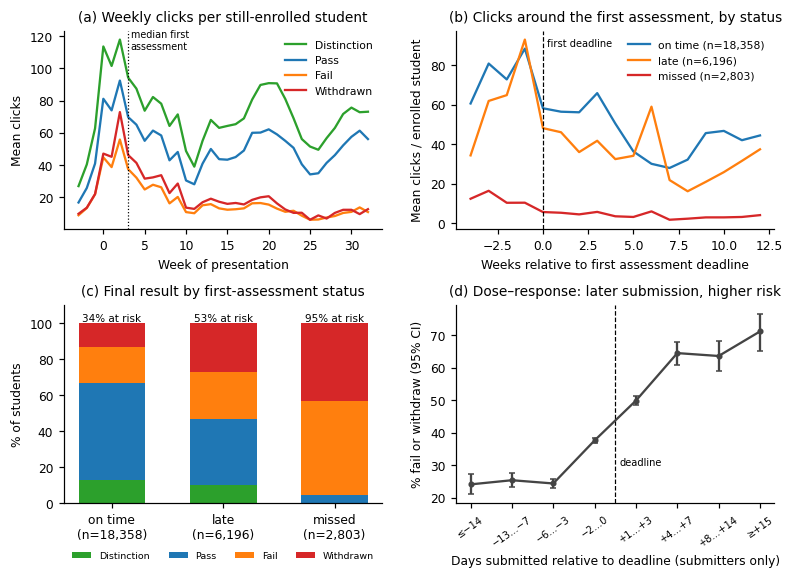

In [31]:
import pandas as pd, numpy as np, json, matplotlib
import matplotlib.pyplot as plt, seaborn as sns
from statsmodels.stats.proportion import proportion_confint
plt.rcParams.update({'font.size':8,'axes.titlesize':9,'axes.labelsize':8,'legend.fontsize':7,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110,'savefig.dpi':200})
K=['code_module','code_presentation','id_student']
base=pd.read_pickle('base.pkl'); wk=pd.read_pickle('weekly.pkl'); wk['clicks']=wk[['content','forum','home','quiz']].sum(axis=1)
DF=pd.read_pickle('h2_C.pkl'); H2=json.load(open('h2_res.json'))
# ===== Fig 1 OULAD temporal
W=list(range(-3,33)); order=['Distinction','Pass','Fail','Withdrawn']; col={'Distinction':'#2ca02c','Pass':'#1f77b4','Fail':'#ff7f0e','Withdrawn':'#d62728'}
w2=wk.merge(base[K+['final_result']],on=K)
def curve(df,b,g,weeks):
    out={}
    for k,bg in b.groupby(g):
        n=np.array([((bg.date_unregistration.isna())|(np.floor(bg.date_unregistration/7)>=w)).sum() for w in weeks])
        s=df[df[g]==k].groupby('week').clicks.sum().reindex(weeks,fill_value=0).values; out[k]=s/np.maximum(n,1)
    return pd.DataFrame(out,index=weeks)
fig,ax=plt.subplots(2,2,figsize=(7.2,5.3))
a=ax[0,0]; c1=curve(w2,base,'final_result',W)
for g in order: a.plot(W,c1[g],color=col[g],label=g,lw=1.5)
a.axvline(3,color='k',ls=':',lw=.8); a.text(3.3,112,'median first\nassessment',fontsize=6.3)
a.set_title('(a) Weekly clicks per still-enrolled student'); a.set_xlabel('Week of presentation'); a.set_ylabel('Mean clicks'); a.legend(frameon=False,loc='upper right')
# (b) relative to first deadline by status
b=ax[0,1]; scol={'on time':'#1f77b4','late':'#ff7f0e','missed':'#d62728'}
x=wk.merge(DF[K+['status','date']].rename(columns={'date':'a1'}),on=K); x['rw']=np.floor((x.week*7-x.a1)/7).astype(int)
RW=list(range(-4,13)); DF2=DF.copy(); 
for st in ['on time','late','missed']:
    sub=x[x.status==st]; bg=DF2[DF2.status==st]
    n=np.array([((bg.date_unregistration.isna())|(bg.date_unregistration>=bg.date+7*w)).sum() for w in RW])
    s=sub.groupby('rw').clicks.sum().reindex(RW,fill_value=0).values
    b.plot(RW,s/np.maximum(n,1),color=scol[st],lw=1.5,label=f'{st} (n={len(bg):,})')
b.axvline(0,color='k',ls='--',lw=.8); b.text(.2,b.get_ylim()[1]*.92,'first deadline',fontsize=6.5)
b.set_title('(b) Clicks around the first assessment, by status'); b.set_xlabel('Weeks relative to first assessment deadline'); b.set_ylabel('Mean clicks / enrolled student'); b.legend(frameon=False,loc='upper right')
# (c) outcome composition by status
c=ax[1,0]; r=DF.groupby('status').final_result.value_counts(normalize=True).unstack()[order]*100; bot=np.zeros(3)
for g in order: c.bar(range(3),r[g].values,bottom=bot,color=col[g],label=g,width=.6); bot+=r[g].values
for i,st in enumerate(r.index): c.text(i,101,f'{(r.loc[st,"Fail"]+r.loc[st,"Withdrawn"]):.0f}% at risk',ha='center',fontsize=6.8)
c.set_xticks(range(3)); c.set_xticklabels([f'{s}\n(n={int((DF.status==s).sum()):,})' for s in r.index]); c.set_ylim(0,110); c.set_ylabel('% of students'); c.set_title('(c) Final result by first-assessment status'); c.legend(frameon=False,ncol=4,fontsize=6.2,loc='upper center',bbox_to_anchor=(.5,-.2))
# (d) dose-response latency
d=ax[1,1]; S=DF[DF.status!='missed'].copy(); S['lat']=S.date_submitted-S.date
bins=[-100,-14,-7,-3,0,3,7,14,1000]; labs=['≤−14','−13…−7','−6…−3','−2…0','+1…+3','+4…+7','+8…+14','≥+15']
S['lb']=pd.cut(S.lat,bins,labels=labs); g=S.groupby('lb').at_risk.agg(['sum','size'])
lo,hi=proportion_confint(g['sum'],g['size'],method='wilson'); p=g['sum']/g['size']
d.errorbar(range(len(g)),p*100,yerr=[(p-lo)*100,(hi-p)*100],fmt='o-',color='#444',capsize=2,ms=3)
d.axvline(3.5,color='k',ls='--',lw=.8); d.text(3.6,30,'deadline',fontsize=6.5)
d.set_xticks(range(len(g))); d.set_xticklabels(labs,rotation=35,fontsize=6.5); d.set_xlabel('Days submitted relative to deadline (submitters only)'); d.set_ylabel('% fail or withdraw (95% CI)'); d.set_title('(d) Dose–response: later submission, higher risk')
plt.tight_layout(); plt.savefig(FIGS/'f1_oulad_temporal.png'); plt.show()

### Figure 3 – OULAD prediction (H1)

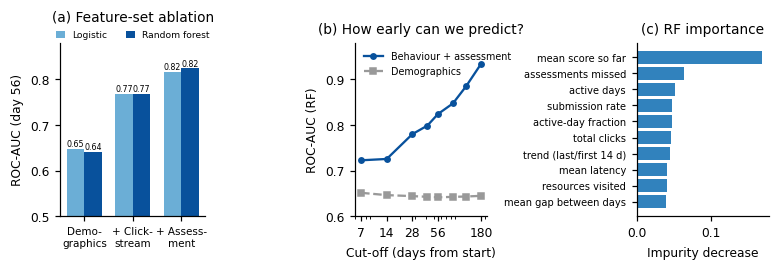

In [32]:
# ===== Fig 2 OULAD ML
r=json.load(open('oulad_res.json')); sw=pd.read_pickle('oulad_sweep.pkl'); imp=pd.read_pickle('oulad_imp.pkl')
fig,ax=plt.subplots(1,3,figsize=(7.2,2.5),gridspec_kw={'width_ratios':[1.1,1,1]})
a=ax[0]; sets=['Demographics','+ Clickstream','+ Clickstream + Assessment']; x=np.arange(3); w=.36
for j,(mdl,cc,lab) in enumerate([('lr','#6baed6','Logistic'),('rf','#08519c','Random forest')]):
    v=[r[f'{s}|{mdl}']['auc'] for s in sets]; a.bar(x+(j-.5)*w,v,w,color=cc,label=lab)
    for i,vv in enumerate(v): a.text(i+(j-.5)*w,vv+.005,f'{vv:.2f}',ha='center',fontsize=5.2)
a.set_xticks(x); a.set_xticklabels(['Demo-\ngraphics','+ Click-\nstream','+ Assess-\nment'],fontsize=6.8); a.set_ylim(.5,.88); a.set_ylabel('ROC-AUC (day 56)'); a.set_title('(a) Feature-set ablation',pad=14); a.legend(frameon=False,loc='lower center',bbox_to_anchor=(.5,.97),ncol=2,fontsize=6,handlelength=1)
b=ax[1]; b.plot(sw.cutoff,sw.auc,'o-',color='#08519c',label='Behaviour + assessment',ms=3.5); b.plot(sw.cutoff,sw.auc_demo,'s--',color='#999',label='Demographics',ms=3.5)
b.set_xscale('log'); b.set_xticks([7,14,28,56,180]); b.set_xticklabels([7,14,28,56,180]); b.set_xlabel('Cut-off (days from start)'); b.set_ylabel('ROC-AUC (RF)'); b.set_title('(b) How early can we predict?'); b.set_ylim(.6,.98); b.legend(frameon=False,fontsize=6.3,loc='upper left')
c=ax[2]; nice={'score_mean':'mean score so far','missed':'assessments missed','active_days':'active days','sub_rate':'submission rate','active_frac':'active-day fraction','clicks':'total clicks','trend':'trend (last/first 14 d)','lat_mean':'mean latency','nsites':'resources visited','gap_mean':'mean gap between days'}
t=imp.head(10)[::-1]; c.barh([nice.get(i,i) for i in t.index],t.values,color='#3182bd'); c.set_title('(c) RF importance'); c.set_xlabel('Impurity decrease'); c.tick_params(axis='y',labelsize=6.5)
plt.tight_layout(); plt.savefig(FIGS/'f2_oulad_ml.png'); plt.show()

### Figure 2 – Moodle over time

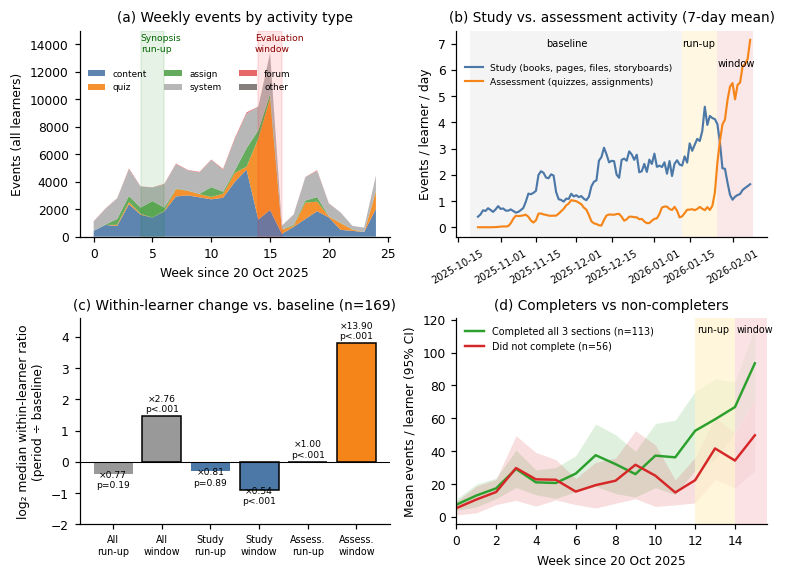

In [33]:
# ===== Fig 3 Moodle temporal
m=pd.read_pickle('m.pkl'); F=pd.read_pickle('h3_F.pkl'); dly=pd.read_pickle('h4_daily.pkl'); H4=pd.read_pickle('h4_table.pkl')
T0=pd.Timestamp('2025-10-20'); RU=pd.Timestamp('2026-01-12'); OPEN=pd.Timestamp('2026-01-26'); CLOSE=pd.Timestamp('2026-02-09')
fig,ax=plt.subplots(2,2,figsize=(7.2,5.3))
a=ax[0,0]; mm=m[m.click&(m.t>=T0)&(m.t<pd.Timestamp('2026-04-13'))].copy(); mm['week']=(mm.t-T0).dt.days//7
cats=['content','quiz','assign','system','forum','other']; cols=['#4C78A8','#F58518','#54A24B','#B0B0B0','#E45756','#79706E']
t=mm.groupby(['week','cat']).size().unstack(fill_value=0).reindex(columns=cats,fill_value=0).reindex(range(25),fill_value=0)
a.stackplot(t.index,t.T.values,labels=cats,colors=cols,alpha=.9)
wkn=lambda d:(pd.Timestamp(d)-T0).days/7
a.axvspan(wkn('2025-11-17'),wkn('2025-12-01'),color='green',alpha=.1); a.axvspan(wkn('2026-01-26'),wkn('2026-02-09'),color='red',alpha=.1)
a.set_ylim(0,15000); a.text(wkn('2025-11-17'),13500,'Synopsis\nrun-up',fontsize=6,color='darkgreen'); a.text(wkn('2026-01-26')-.3,13500,'Evaluation\nwindow',fontsize=6,color='darkred')
a.set_title('(a) Weekly events by activity type'); a.set_xlabel('Week since 20 Oct 2025'); a.set_ylabel('Events (all learners)'); a.legend(ncol=3,frameon=False,fontsize=5.8,loc='upper left',bbox_to_anchor=(0,.85))
b=ax[0,1]; dl=dly.loc[(dly.index>=T0)&(dly.index<CLOSE)].rolling(7,min_periods=1).mean()
b.plot(dl.index,dl.study,color='#4C78A8',label='Study (books, pages, files, storyboards)',lw=1.4); b.plot(dl.index,dl.assess,color='#F58518',label='Assessment (quizzes, assignments)',lw=1.4)
for (s,e,cc) in [(T0,RU,'#eeeeee'),(RU,OPEN,'#fff3cd'),(OPEN,CLOSE,'#f8d7da')]: b.axvspan(s,e,color=cc,alpha=.6,lw=0)
b.text(T0+pd.Timedelta(days=30),b.get_ylim()[1]*.92,'baseline',fontsize=6.5); b.text(RU,b.get_ylim()[1]*.92,'run-up',fontsize=6.5); b.text(OPEN,b.get_ylim()[1]*.82,'window',fontsize=6.5)
b.set_title('(b) Study vs. assessment activity (7-day mean)'); b.set_ylabel('Events / learner / day'); b.legend(frameon=False,fontsize=6,loc='upper left',bbox_to_anchor=(0,.88)); b.tick_params(axis='x',labelsize=6.5,rotation=30)
c=ax[1,0]; h=H4.copy(); h['lab']=h.activity.map({'all':'All','study':'Study','assess':'Assess.'})+'\n'+h.period.map({'runup':'run-up','window':'window'})
cc=['#999','#999','#4C78A8','#4C78A8','#F58518','#F58518']
c.bar(range(6),np.log2(h.median_ratio),color=cc,edgecolor=['k' if p<0.05/6 else 'none' for p in h.p],linewidth=1)
for i,(rv,p) in enumerate(zip(h.median_ratio,h.p)): c.text(i,np.log2(rv)+(.15 if rv>=1 else -.45),f'×{rv:.2f}\n'+('p<.001' if p<.001 else f'p={p:.2f}'),ha='center',fontsize=6)
c.axhline(0,color='k',lw=.7); c.set_xticks(range(6)); c.set_xticklabels(h.lab,fontsize=6.3); c.set_ylabel('log₂ median within-learner ratio\n(period ÷ baseline)'); c.set_ylim(-2,4.6); c.set_title('(c) Within-learner change vs. baseline (n=169)')
d=ax[1,1]
cw=m[m.click&m.u.isin(F.index)&(m.t>=T0)&(m.t<CLOSE)]
Wk=cw.groupby(['u','week']).size().unstack(fill_value=0).reindex(index=F.index,columns=range(16),fill_value=0)
for yv,colr,lab in [(1,'#2ca02c','Completed all 3 sections'),(0,'#d62728','Did not complete')]:
    g=Wk[F.y==yv]; mu=g.mean(); se=g.std()/np.sqrt(len(g))
    d.plot(mu.index,mu.values,color=colr,lw=1.6,label=f'{lab} (n={len(g)})'); d.fill_between(mu.index,mu-1.96*se,mu+1.96*se,color=colr,alpha=.15,lw=0)
d.axvspan(12,14,color='#fff3cd',alpha=.7,lw=0); d.axvspan(14,15.6,color='#f8d7da',alpha=.7,lw=0)
d.text(12.1,d.get_ylim()[1]*.93,'run-up',fontsize=6.3); d.text(14.1,d.get_ylim()[1]*.93,'window',fontsize=6.3)
d.set_xlim(0,15.6); d.set_title('(d) Completers vs non-completers'); d.set_xlabel('Week since 20 Oct 2025'); d.set_ylabel('Mean events / learner (95% CI)'); d.legend(frameon=False,fontsize=6.3,loc='upper left')
plt.tight_layout(); plt.savefig(FIGS/'f3_moodle_temporal.png'); plt.show()

### Figure 4 – Moodle H3 inference and prediction

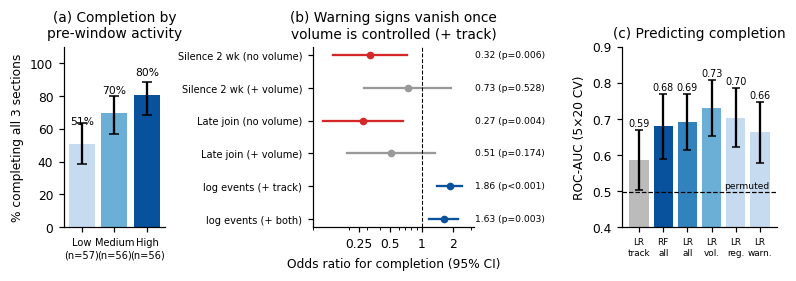

In [34]:
# ===== Fig 4 Moodle inference/ML
R=json.load(open('h3_res.json'))
fig,ax=plt.subplots(1,3,figsize=(7.2,2.6),gridspec_kw={'width_ratios':[.75,1.2,1.15]})
a=ax[0]; t=pd.DataFrame(R['by_tertile']); k=(t['mean']*t['size']).round().astype(int); lo,hi=proportion_confint(k,t['size'],method='wilson')
a.bar(range(3),t['mean']*100,yerr=[(t['mean']-lo)*100,(hi-t['mean'])*100],color=['#c6dbef','#6baed6','#08519c'],capsize=3)
for i,v in enumerate(t['mean']): a.text(i,v*100+12,f'{v*100:.0f}%',ha='center',fontsize=7)
a.set_xticks(range(3)); a.set_xticklabels([f'{v}\n(n={n})' for v,n in zip(t.vt,t['size'])],fontsize=6.5); a.set_ylim(0,110); a.set_ylabel('% completing all 3 sections'); a.set_title('(a) Completion by\npre-window activity')
b=ax[1]; L=R['logit']; rows=[('Silence 2 wk (no volume)',L['Silence only']['silent2']),('Silence 2 wk (+ volume)',L['Silence + volume']['silent2']),('Late join (no volume)',L['Late join only']['late']),('Late join (+ volume)',L['Late join + volume']['late']),('log events (+ track)',L['Volume only']['lv']),('log events (+ both)',L['All three']['lv'])]
for i,(lab,(o,l,h_,p)) in enumerate(rows[::-1]):
    cc='#08519c' if 'log events' in lab else ('#d62728' if 'no volume' in lab else '#999')
    b.plot([l,h_],[i,i],color=cc,lw=1.5); b.plot(o,i,'o',color=cc,ms=4); b.text(3.25,i,f'{o:.2f} ('+('p<0.001' if p<0.001 else f'p={p:.3f}')+')',va='center',fontsize=6)
b.axvline(1,color='k',ls='--',lw=.7); b.set_xscale('log'); b.set_xlim(.09,3.2); b.set_xticks([.25,.5,1,2]); b.set_xticklabels(['0.25','0.5','1','2'])
b.set_yticks(range(len(rows))); b.set_yticklabels([r_[0] for r_ in rows[::-1]],fontsize=6.5); b.set_xlabel('Odds ratio for completion (95% CI)'); b.set_title('(b) Warning signs vanish once\nvolume is controlled (+ track)')
c=ax[2]; ml=R['ml']; keys=[('Track only (Synopsis)|lr','LR\ntrack'),('All behavioural features|rf','RF\nall'),('All behavioural features|lr','LR\nall'),('Volume only (log events)|lr','LR\nvol.'),('Regularity + mix (no volume)|lr','LR\nreg.'),('Warning signs only (silence, late join)|lr','LR\nwarn.')]
v=[ml[k_]['auc'] for k_,_ in keys]; s=[ml[k_]['sd'] for k_,_ in keys]
c.bar(range(6),v,yerr=s,color=['#bbbbbb','#08519c','#3182bd','#6baed6','#c6dbef','#c6dbef'],capsize=2.5); c.axhline(R['null_mean'],color='k',ls='--',lw=.8); c.text(5.4,R['null_mean']+.01,'permuted',fontsize=6,ha='right')
for i,vv in enumerate(v): c.text(i,vv+s[i]+.01,f'{vv:.2f}',ha='center',fontsize=6.3)
c.set_xticks(range(6)); c.set_xticklabels([k_[1] for k_ in keys],fontsize=5.8); c.set_ylim(.4,.9); c.set_ylabel('ROC-AUC (5×20 CV)'); c.set_title('(c) Predicting completion')
plt.tight_layout(); plt.savefig(FIGS/'f4_moodle_ml.png'); plt.show()

## Summary of results

| | Hypothesis | Verdict | Key evidence |
|---|---|---|---|
| H1 | Early behaviour (clicks and assessment) beats demographics | Supported | AUC 0.82 vs 0.65 at day 56 (clickstream alone 0.77); 0.78 by day 28 |
| H2 | First-assessment timeliness (banked marks excluded) | Supported | Missed: OR 20.6; late: OR 2.2 (fully adjusted); +7% odds per day late |
| H3 | Engagement predicts completion (controlling for assessment track) | Supported (volume) | OR 1.86 per log-unit; warning signs vanish once volume is controlled; same in non-project learners |
| H4 | Deadline-driven activity | Supported | Study falls to ×0.54 in the evaluation window and does not rise in the run-up; the assessment rise is largely mechanical |

See the report for interpretation, practical implications and limitations.